# Employee Attrition Prediction

## Phase 1: Data Collection and Understanding

### Project Overview
This project analyzes employee attrition patterns
and develops a machine learning solution to estimate
employee attrition likelihood.

### Business Objective
- Understand employee attrition patterns.
- Analyze employee demographics.
- Explore job satisfaction and salary.
- Identify factors associated with employees leaving.
- Prepare data for machine learning.

### Technology Stack
- Python
- Pandas
- NumPy
- Matplotlib
- Seaborn
- MySQL
- Scikit-learn
- Power BI

### Dataset
IBM HR Analytics Employee Attrition & Performance

### Target Variable
Attrition (Yes / No)

### Project Phase
Phase 1 - Data Collection and Understanding

In [1]:
# ==========================================
# 1. IMPORT REQUIRED LIBRARIES
# ==========================================

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from pathlib import Path
import os
import warnings

warnings.filterwarnings("ignore")

# Display configuration
pd.set_option("display.max_columns", None)
pd.set_option("display.max_rows", 50)
pd.set_option("display.width", 120)

# Visualization style
sns.set_theme(style="whitegrid")

print("All libraries imported successfully!")

All libraries imported successfully!


In [2]:
# ==========================================
# 2. DATASET PATH CONFIGURATION
# ==========================================

PROJECT_DIR = Path.cwd()

# If the notebook kernel starts inside notebooks/,
# move one level up to the main project directory.

if PROJECT_DIR.name == "notebooks":
    PROJECT_DIR = PROJECT_DIR.parent

DATASET_NAME = "HR-Employee-Attrition.csv"

DATASET_PATH = (
    PROJECT_DIR / "data" / "raw" / DATASET_NAME
)

print("Project Directory:", PROJECT_DIR)
print("Dataset Path:", DATASET_PATH)

if not DATASET_PATH.exists():
    raise FileNotFoundError(
        "Dataset not found! Please place the CSV file "
        "inside data/raw/ folder."
    )

print("\nDataset file found successfully!")

Project Directory: c:\Users\gupta\OneDrive\Desktop\Employee-Attrition-Prediction
Dataset Path: c:\Users\gupta\OneDrive\Desktop\Employee-Attrition-Prediction\data\raw\HR-Employee-Attrition.csv

Dataset file found successfully!


In [3]:
# ==========================================
# 3. LOAD DATASET
# ==========================================

df = pd.read_csv(DATASET_PATH)

print("Dataset loaded successfully!")

print("Number of Rows:", df.shape[0])
print("Number of Columns:", df.shape[1])

Dataset loaded successfully!
Number of Rows: 1470
Number of Columns: 35


In [17]:
# ==========================================
# EMPLOYEE ID CONFIGURATION
# ==========================================

# Rename EmployeeNumber to EmployeeID

df.rename(
    columns={
        "EmployeeNumber": "EmployeeID"
    },
    inplace=True
)

# Display employee IDs

print("Employee ID column added successfully!")

print(df[["EmployeeID"]].head(10))

# Check unique employee IDs

print("\nTotal Employee IDs:", df["EmployeeID"].nunique())

print("Duplicate Employee IDs:",
      df["EmployeeID"].duplicated().sum())

print("Missing Employee IDs:",
      df["EmployeeID"].isnull().sum())

Employee ID column added successfully!
   EmployeeID
0           1
1           2
2           4
3           5
4           7
5           8
6          10
7          11
8          12
9          13

Total Employee IDs: 1470
Duplicate Employee IDs: 0
Missing Employee IDs: 0


In [4]:

# 4. FIRST FIVE RECORDS

df.head()

,Age,Attrition,BusinessTravel,DailyRate,Department,DistanceFromHome,Education,EducationField,EmployeeCount,EmployeeNumber,EnvironmentSatisfaction,Gender,HourlyRate,JobInvolvement,JobLevel,JobRole,JobSatisfaction,MaritalStatus,MonthlyIncome,MonthlyRate,NumCompaniesWorked,Over18,OverTime,PercentSalaryHike,PerformanceRating,RelationshipSatisfaction,StandardHours,StockOptionLevel,TotalWorkingYears,TrainingTimesLastYear,WorkLifeBalance,YearsAtCompany,YearsInCurrentRole,YearsSinceLastPromotion,YearsWithCurrManager
0,41,Yes,Travel_Rarely,1102,Sales,1,2,Life Sciences,1,1,2,Female,94,3,2,Sales Executive,4,Single,5993,19479,8,Y,Yes,11,3,1,80,0,8,0,1,6,4,0,5
1,49,No,Travel_Frequently,279,Research & Development,8,1,Life Sciences,1,2,3,Male,61,2,2,Research Scientist,2,Married,5130,24907,1,Y,No,23,4,4,80,1,10,3,3,10,7,1,7
2,37,Yes,Travel_Rarely,1373,Research & Development,2,2,Other,1,4,4,Male,92,2,1,Laboratory Technician,3,Single,2090,2396,6,Y,Yes,15,3,2,80,0,7,3,3,0,0,0,0
3,33,No,Travel_Frequently,1392,Research & Development,3,4,Life Sciences,1,5,4,Female,56,3,1,Research Scientist,3,Married,2909,23159,1,Y,Yes,11,3,3,80,0,8,3,3,8,7,3,0
4,27,No,Travel_Rarely,591,Research & Development,2,1,Medical,1,7,1,Male,40,3,1,Laboratory Technician,2,Married,3468,16632,9,Y,No,12,3,4,80,1,6,3,3,2,2,2,2


In [ ]:
# ==========================================
# 5. LAST FIVE RECORDS
# ==========================================

df.tail()

In [ ]:
# ==========================================
# 6. DATASET INFORMATION
# ==========================================

df.info()

In [ ]:
# ==========================================
# 7. COLUMN NAMES
# ==========================================

print("Total Columns:", len(df.columns))

for index, column in enumerate(df.columns, start=1):
    print(index, "-", column)

In [7]:
# ==========================================
# 8. STATISTICAL SUMMARY
# ==========================================


df.describe()

,Age,DailyRate,DistanceFromHome,Education,EmployeeCount,EmployeeNumber,EnvironmentSatisfaction,HourlyRate,JobInvolvement,JobLevel,JobSatisfaction,MonthlyIncome,MonthlyRate,NumCompaniesWorked,PercentSalaryHike,PerformanceRating,RelationshipSatisfaction,StandardHours,StockOptionLevel,TotalWorkingYears,TrainingTimesLastYear,WorkLifeBalance,YearsAtCompany,YearsInCurrentRole,YearsSinceLastPromotion,YearsWithCurrManager
count,1470.000000,1470.000000,1470.000000,1470.000000,1470.0,1470.000000,1470.000000,1470.000000,1470.000000,1470.000000,1470.000000,1470.000000,1470.000000,1470.000000,1470.000000,1470.000000,1470.000000,1470.0,1470.000000,1470.000000,1470.000000,1470.000000,1470.000000,1470.000000,1470.000000,1470.000000
mean,36.923810,802.485714,9.192517,2.912925,1.0,1024.865306,2.721769,65.891156,2.729932,2.063946,2.728571,6502.931293,14313.103401,2.693197,15.209524,3.153741,2.712245,80.0,0.793878,11.279592,2.799320,2.761224,7.008163,4.229252,2.187755,4.123129
std,9.135373,403.509100,8.106864,1.024165,0.0,602.024335,1.093082,20.329428,0.711561,1.106940,1.102846,4707.956783,7117.786044,2.498009,3.659938,0.360824,1.081209,0.0,0.852077,7.780782,1.289271,0.706476,6.126525,3.623137,3.222430,3.568136
min,18.000000,102.000000,1.000000,1.000000,1.0,1.000000,1.000000,30.000000,1.000000,1.000000,1.000000,1009.000000,2094.000000,0.000000,11.000000,3.000000,1.000000,80.0,0.000000,0.000000,0.000000,1.000000,0.000000,0.000000,0.000000,0.000000
25%,30.000000,465.000000,2.000000,2.000000,1.0,491.250000,2.000000,48.000000,2.000000,1.000000,2.000000,2911.000000,8047.000000,1.000000,12.000000,3.000000,2.000000,80.0,0.000000,6.000000,2.000000,2.000000,3.000000,2.000000,0.000000,2.000000
50%,36.000000,802.000000,7.000000,3.000000,1.0,1020.500000,3.000000,66.000000,3.000000,2.000000,3.000000,4919.000000,14235.500000,2.000000,14.000000,3.000000,3.000000,80.0,1.000000,10.000000,3.000000,3.000000,5.000000,3.000000,1.000000,3.000000
75%,43.000000,1157.000000,14.000000,4.000000,1.0,1555.750000,4.000000,83.750000,3.000000,3.000000,4.000000,8379.000000,20461.500000,4.000000,18.000000,3.000000,4.000000,80.0,1.000000,15.000000,3.000000,3.000000,9.000000,7.000000,3.000000,7.000000
max,60.000000,1499.000000,29.000000,5.000000,1.0,2068.000000,4.000000,100.000000,4.000000,5.000000,4.000000,19999.000000,26999.000000,9.000000,25.000000,4.000000,4.000000,80.0,3.000000,40.000000,6.000000,4.000000,40.000000,18.000000,15.000000,17.000000


In [8]:
# ==========================================
# 9. MISSING VALUE ANALYSIS
# ==========================================

missing_values = pd.DataFrame({
    "Missing Count": df.isnull().sum(),
    "Missing Percentage": (
        df.isnull().sum() / len(df) * 100
    )
})

missing_values = missing_values.sort_values(
    by="Missing Count",
    ascending=False
)

missing_values

,Missing Count,Missing Percentage
Age,0,0.0
Attrition,0,0.0
BusinessTravel,0,0.0
DailyRate,0,0.0
Department,0,0.0
DistanceFromHome,0,0.0
Education,0,0.0
EducationField,0,0.0
EmployeeCount,0,0.0
EmployeeNumber,0,0.0


In [9]:
# ==========================================
# 10. DUPLICATE RECORD ANALYSIS
# ==========================================

duplicate_count = df.duplicated().sum()

print("Total Duplicate Records:", duplicate_count)

if duplicate_count == 0:
    print("No duplicate records found.")
else:
    print("Duplicate records need investigation.")

Total Duplicate Records: 0
No duplicate records found.


In [10]:
# ==========================================
# 11. TARGET VARIABLE ANALYSIS
# ==========================================

print("Attrition Distribution:")

print(df["Attrition"].value_counts())

print("\nAttrition Percentage:")

print(
    df["Attrition"].value_counts(normalize=True) * 100
)

Attrition Distribution:
Attrition
No     1233
Yes     237
Name: count, dtype: int64

Attrition Percentage:
Attrition
No     83.877551
Yes    16.122449
Name: proportion, dtype: float64


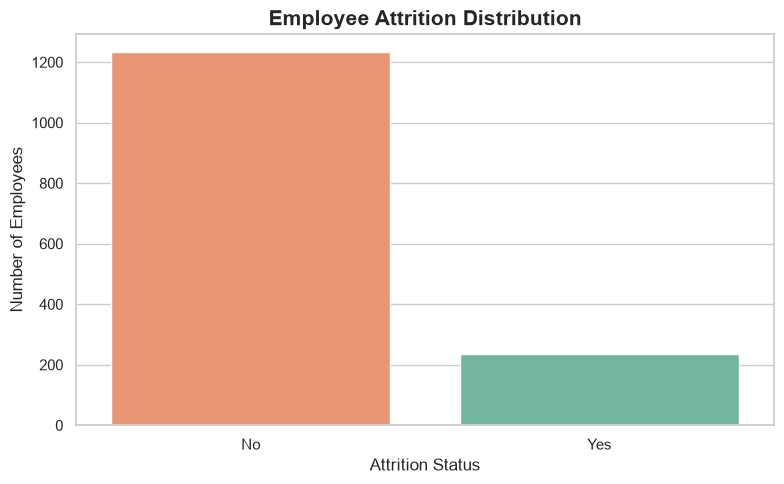

In [11]:
# ==========================================
# 12. ATTRITION DISTRIBUTION CHART
# ==========================================

plt.figure(figsize=(8, 5))

sns.countplot(
    data=df,
    x="Attrition",
    hue="Attrition",
    order=["No", "Yes"],
    palette="Set2",
    legend=False
)

plt.title(
    "Employee Attrition Distribution",
    fontsize=15,
    fontweight="bold"
)

plt.xlabel("Attrition Status")
plt.ylabel("Number of Employees")

plt.tight_layout()

plt.show()

In [12]:
# ==========================================
# 13. IDENTIFY DATA TYPES
# ==========================================

numerical_columns = df.select_dtypes(
    include=["int64", "float64"]
).columns.tolist()

categorical_columns = df.select_dtypes(
    include=["object"]
).columns.tolist()

print("Numerical Columns:", len(numerical_columns))
print("Categorical Columns:", len(categorical_columns))

print("\nNumerical Features:")
print(numerical_columns)

print("\nCategorical Features:")
print(categorical_columns)

Numerical Columns: 26
Categorical Columns: 9

Numerical Features:
['Age', 'DailyRate', 'DistanceFromHome', 'Education', 'EmployeeCount', 'EmployeeNumber', 'EnvironmentSatisfaction', 'HourlyRate', 'JobInvolvement', 'JobLevel', 'JobSatisfaction', 'MonthlyIncome', 'MonthlyRate', 'NumCompaniesWorked', 'PercentSalaryHike', 'PerformanceRating', 'RelationshipSatisfaction', 'StandardHours', 'StockOptionLevel', 'TotalWorkingYears', 'TrainingTimesLastYear', 'WorkLifeBalance', 'YearsAtCompany', 'YearsInCurrentRole', 'YearsSinceLastPromotion', 'YearsWithCurrManager']

Categorical Features:
['Attrition', 'BusinessTravel', 'Department', 'EducationField', 'Gender', 'JobRole', 'MaritalStatus', 'Over18', 'OverTime']


In [13]:
# ==========================================
# 14. UNIQUE VALUE ANALYSIS
# ==========================================

unique_values = pd.DataFrame({
    "Column": df.columns,
    "Unique Values": [
        df[column].nunique()
        for column in df.columns
    ]
})

unique_values

,Column,Unique Values
0,Age,43
1,Attrition,2
2,BusinessTravel,3
3,DailyRate,886
4,Department,3
5,DistanceFromHome,29
6,Education,5
7,EducationField,6
8,EmployeeCount,1
9,EmployeeNumber,1470


In [14]:
# ==========================================
# 15. IDENTIFY CONSTANT COLUMNS
# ==========================================

constant_columns = [
    column
    for column in df.columns
    if df[column].nunique() <= 1
]

print("Constant Columns:")

print(constant_columns)

Constant Columns:
['EmployeeCount', 'Over18', 'StandardHours']


In [15]:
# ==========================================
# 16. SAVE DATA QUALITY REPORT
# ==========================================

report_dir = PROJECT_DIR / "reports"

report_dir.mkdir(
    parents=True,
    exist_ok=True
)

quality_report = pd.DataFrame({
    "Column": df.columns,
    "Data Type": df.dtypes.astype(str).values,
    "Missing Values": df.isnull().sum().values,
    "Unique Values": df.nunique().values
})

quality_report.to_csv(
    report_dir / "data_quality_report.csv",
    index=False
)

print("Data quality report saved successfully!")

print(
    report_dir / "data_quality_report.csv"
)

Data quality report saved successfully!
c:\Users\gupta\OneDrive\Desktop\Employee-Attrition-Prediction\reports\data_quality_report.csv


In [16]:
# ==========================================
# 17. PHASE 1 SUMMARY
# ==========================================

print("=" * 50)
print("EMPLOYEE ATTRITION PROJECT")
print("PHASE 1 - DATA COLLECTION SUMMARY")
print("=" * 50)

print("Total Employees:", df.shape[0])

print("Total Features:", df.shape[1])

print("Missing Values:", df.isnull().sum().sum())

print("Duplicate Records:", df.duplicated().sum())

print("Attrition Yes:",
      (df["Attrition"] == "Yes").sum())

print("Attrition No:",
      (df["Attrition"] == "No").sum())

print("Constant Columns:", constant_columns)

print("=" * 50)

print("PHASE 1 DATA COLLECTION COMPLETED!")

EMPLOYEE ATTRITION PROJECT
PHASE 1 - DATA COLLECTION SUMMARY
Total Employees: 1470
Total Features: 35
Missing Values: 0
Duplicate Records: 0
Attrition Yes: 237
Attrition No: 1233
Constant Columns: ['EmployeeCount', 'Over18', 'StandardHours']
PHASE 1 DATA COLLECTION COMPLETED!


In [18]:
# ==========================================
# SAVE DATASET WITH EMPLOYEE ID
# ==========================================

processed_path = (
    PROJECT_DIR / "data" / "processed"
    / "employee_attrition_with_id.csv"
)

df.to_csv(processed_path, index=False)

print("Updated dataset saved successfully!")
print(processed_path)

Updated dataset saved successfully!
c:\Users\gupta\OneDrive\Desktop\Employee-Attrition-Prediction\data\processed\employee_attrition_with_id.csv
